# DIANN vs Spectronaut — DEA Result Comparison

Compares MSqRob differential expression results from two search engines run on the same single-cell proteomics data:

| Source | Path | Model |
|---|---|---|
| **DIANN** | `Data/MSqRob/DIANN/second_pass/` | Integrated (all plates, full covariate model) + per-plate |
| **Spectronaut** | `Data/MSqRob/per_plate/` | Per-plate only |

Sections:
1. **Detection** — how many proteins are quantified per plate and in total per tool
2. **Protein overlap** — which proteins are detected by both / either tool
3. **logFC concordance** — scatter plot of fold-change estimates for shared proteins
4. **Significance overlap** — proteins significant in DIANN only / Spectronaut only / both / neither
5. **Per-plate logFC correlation** — plate-level Pearson r and scatter grid

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy import stats
from upsetplot import UpSet, from_memberships

# ── Paths ────────────────────────────────────────────────────────────────────
ROOT          = os.path.normpath(os.path.join(os.getcwd(), "../../"))
DIANN_DIR     = os.path.join(ROOT, "Data", "MSqRob", "DIANN", 'v2.6', "second_pass")
SPECT_PP_DIR  = os.path.join(ROOT, "Data", "MSqRob", "per_plate")
SPECT_INT_DIR = os.path.join(ROOT, "Data", "MSqRob", "DEA_results", "csv")
FIG_DIR       = os.path.join(ROOT, "Figures", "software_comparison")
for fmt in ("pdf", "png", "svg"):
    os.makedirs(os.path.join(FIG_DIR, fmt), exist_ok=True)

# ── Thresholds ───────────────────────────────────────────────────────────────
FDR_THRESHOLD = 0.01
FC_THRESHOLD  = 0.5   # |log2FC| threshold

PLATE_ORDER = ["Astral_1", "Astral_2", "Astral_3", "Astral_4",
               "Astral_5", "Astral_6", "timsTOF_1", "timsTOF_2", "timsTOF_3"]

PALETTE = {"DIANN": "#2E86AB", "Spectronaut": "#E84855", "Both": "#5C4B8A"}

sns.set_theme(style="whitegrid", font_scale=1.1)

def save_fig(name, **kwargs):
    for fmt in ("pdf", "png", "svg"):
        plt.savefig(os.path.join(FIG_DIR, fmt, f"{name}.{fmt}"), **kwargs)

print(f"DIANN dir          : {DIANN_DIR}")
print(f"Spectronaut per-pl : {SPECT_PP_DIR}")
print(f"Spectronaut integr : {SPECT_INT_DIR}")
print(f"Figures            : {FIG_DIR}")

DIANN dir          : /home/sam/SCI/SCI/Data/MSqRob/DIANN/v2.6/second_pass
Spectronaut per-pl : /home/sam/SCI/SCI/Data/MSqRob/per_plate
Spectronaut integr : /home/sam/SCI/SCI/Data/MSqRob/DEA_results/csv
Figures            : /home/sam/SCI/SCI/Figures/software_comparison


## 1. Load Data

In [2]:
# ── DIANN integrated models ───────────────────────────────────────────────────
diann_all  = pd.read_csv(os.path.join(DIANN_DIR, "res_all.csv"))
diann_norm = pd.read_csv(os.path.join(DIANN_DIR, "res_norm.csv"))

# ── DIANN per-plate ───────────────────────────────────────────────────────────
diann_pp = pd.read_csv(os.path.join(DIANN_DIR, "per_plate", "combined.csv"))

# ── Spectronaut integrated ────────────────────────────────────────────────────
spect_int = pd.read_csv(os.path.join(SPECT_INT_DIR, "res_all.csv"))

# ── Spectronaut per-plate ─────────────────────────────────────────────────────
spect_pp = pd.read_csv(os.path.join(SPECT_PP_DIR, "combined.csv"))

print("DIANN integrated (full model)   :", diann_all.shape,
      f"  valid: {diann_all.adjPval.notna().sum()}")
print("DIANN per-plate combined        :", diann_pp.shape,
      f"  unique proteins: {diann_pp.protein.nunique()}")
print()
print("Spectronaut integrated          :", spect_int.shape,
      f"  valid: {spect_int.adjPval.notna().sum()}")
print("Spectronaut per-plate combined  :", spect_pp.shape,
      f"  unique proteins: {spect_pp.protein.nunique()}")
print()

# Enforce plate order
diann_pp['plate'] = pd.Categorical(diann_pp['plate'], categories=PLATE_ORDER, ordered=True)
spect_pp['plate'] = pd.Categorical(spect_pp['plate'], categories=PLATE_ORDER, ordered=True)

DIANN integrated (full model)   : (6002, 7)   valid: 4758
DIANN per-plate combined        : (19143, 8)   unique proteins: 2127

Spectronaut integrated          : (6628, 7)   valid: 4730
Spectronaut per-plate combined  : (19377, 8)   unique proteins: 2153



## 2. Protein Detection Comparison

Per-plate protein counts for DIANN and Spectronaut, plus the total number of unique proteins tested in the DIANN integrated model.

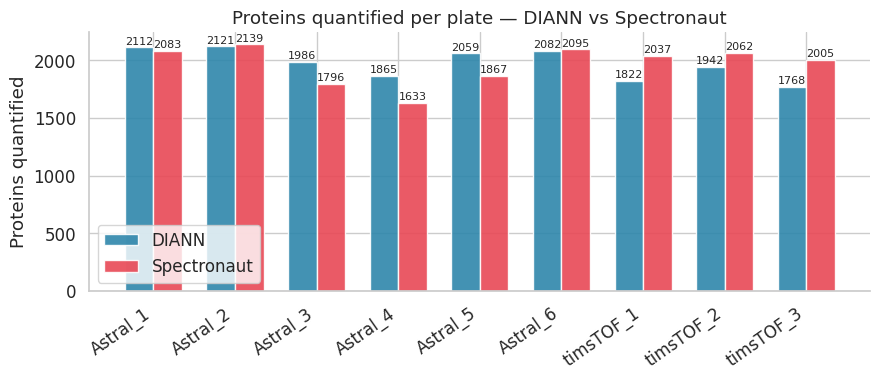


Mean per plate:
DIANN          1973
Spectronaut    1969
dtype: int64

Total unique proteins:
  DIANN integrated (full model) : 4758
  DIANN per-plate union         : 2127
  Spectronaut per-plate union   : 2153


In [3]:
# ── Per-plate protein counts ──────────────────────────────────────────────────
counts_diann = diann_pp.dropna().groupby('plate', observed=True)['protein'].nunique().rename('DIANN')
counts_spect = spect_pp.dropna().groupby('plate', observed=True)['protein'].nunique().rename('Spectronaut')
counts = pd.concat([counts_diann, counts_spect], axis=1).reset_index()

counts_melt = counts.melt(id_vars='plate', var_name='Tool', value_name='n_proteins')

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(PLATE_ORDER))
width = 0.35

for i, tool in enumerate(['DIANN', 'Spectronaut']):
    vals = counts.set_index('plate').reindex(PLATE_ORDER)[tool]
    bars = ax.bar(x + i * width - width / 2, vals, width,
                  label=tool, color=PALETTE[tool], alpha=0.9)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 10,
                str(int(v)), ha='center', va='bottom', fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(PLATE_ORDER, rotation=35, ha='right')
ax.set_ylabel("Proteins quantified")
ax.set_title("Proteins quantified per plate — DIANN vs Spectronaut")
ax.legend()
sns.despine()
plt.tight_layout()
save_fig("D1_proteins_per_plate", bbox_inches='tight')
plt.show()

print("\nMean per plate:")
print(counts[['DIANN', 'Spectronaut']].mean().round(0).astype(int))
print("\nTotal unique proteins:")
print("  DIANN integrated (full model) :", diann_all.adjPval.notna().sum())
print("  DIANN per-plate union         :", diann_pp.protein.nunique())
print("  Spectronaut per-plate union   :", spect_pp.protein.nunique())

## 3. Protein Overlap

UpSet plot comparing proteins quantified across all four result sets:

| Set | Description |
|---|---|
| **DIANN integrated** | Proteins with a valid adjPval in the joint DIANN model |
| **DIANN per-plate union** | Union of proteins tested across all 9 DIANN per-plate models |
| **Spectronaut integrated** | Proteins with a valid adjPval in the joint Spectronaut model |
| **Spectronaut per-plate union** | Union of proteins tested across all 9 Spectronaut per-plate models |

Set sizes:
  DIANN integrated          :  4758
  DIANN per-plate union     :  2127
  Spectronaut integrated    :  4730
  Spectronaut per-plate union:  2153


/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/data.py:303: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linew

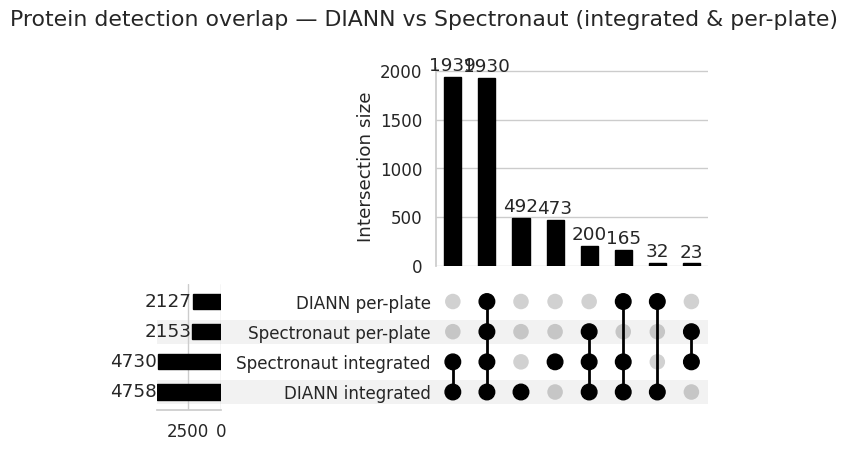


Pairwise overlaps:
  DIANN integrated               vs Spectronaut integrated          |  only A:  524  only B:  496  both: 4234
  DIANN per-plate                vs Spectronaut per-plate           |  only A:  197  only B:  223  both: 1930
  DIANN integrated               vs DIANN per-plate                 |  only A: 2631  only B:    0  both: 2127
  Spectronaut integrated         vs Spectronaut per-plate           |  only A: 2577  only B:    0  both: 2153


In [4]:
# Protein sets — valid adjPval for integrated; all detected for per-plate unions
set_diann_int  = set(diann_all.loc[diann_all.adjPval.notna(), 'protein'])
set_diann_pp   = set(diann_pp['protein'])
set_spect_int  = set(spect_int.loc[spect_int.adjPval.notna(), 'protein'])
set_spect_pp   = set(spect_pp['protein'])

print("Set sizes:")
print(f"  DIANN integrated          : {len(set_diann_int):5d}")
print(f"  DIANN per-plate union     : {len(set_diann_pp):5d}")
print(f"  Spectronaut integrated    : {len(set_spect_int):5d}")
print(f"  Spectronaut per-plate union: {len(set_spect_pp):5d}")

all_proteins = set_diann_int | set_diann_pp | set_spect_int | set_spect_pp

set_labels = [
    ("DIANN integrated",           set_diann_int),
    ("DIANN per-plate",            set_diann_pp),
    ("Spectronaut integrated",     set_spect_int),
    ("Spectronaut per-plate",      set_spect_pp),
]

memberships = [
    [label for label, s in set_labels if p in s]
    for p in all_proteins
]
upset_data = from_memberships(memberships)

fig = plt.figure(figsize=(12, 5))
upset = UpSet(upset_data, subset_size='count', show_counts=True,
              sort_by='cardinality', min_subset_size=5)
upset.plot(fig)
fig.suptitle("Protein detection overlap — DIANN vs Spectronaut (integrated & per-plate)", y=1.01)
save_fig("D2_protein_overlap_upset", bbox_inches='tight')
plt.show()

# Pairwise summary
print("\nPairwise overlaps:")
for (la, sa), (lb, sb) in [
    (set_labels[0], set_labels[2]),   # DIANN int vs Spect int
    (set_labels[1], set_labels[3]),   # DIANN pp  vs Spect pp
    (set_labels[0], set_labels[1]),   # DIANN int vs DIANN pp
    (set_labels[2], set_labels[3]),   # Spect int vs Spect pp
]:
    only_a = len(sa - sb)
    only_b = len(sb - sa)
    both   = len(sa & sb)
    print(f"  {la:30s} vs {lb:30s}  |  only A: {only_a:4d}  only B: {only_b:4d}  both: {both:4d}")

## 4. Integrated logFC Concordance

Compares log₂ fold-change estimates between the two integrated models on shared proteins.

- **DIANN**: `DIANN/second_pass/res_all.csv` — full covariate model across all plates
- **Spectronaut**: `DEA_results/csv/res_all.csv` — equivalent integrated model

Points are coloured by significance status in each tool (FDR < 0.05, |log₂FC| > 0.5).

In [5]:
# Merge the two integrated models on shared proteins with valid adjPval
diann_valid = diann_all.dropna(subset=['adjPval']).copy()
spect_valid = spect_int.dropna(subset=['adjPval']).copy()

merged = diann_valid.merge(spect_valid, on='protein', suffixes=('_diann', '_spect'))
print(f"Shared proteins (DIANN integrated ∩ Spectronaut integrated): {len(merged)}")

def is_sig(adjpval, logfc, fdr=FDR_THRESHOLD, fc=FC_THRESHOLD):
    return (adjpval < fdr) & (np.abs(logfc) > fc)

merged['sig_diann'] = is_sig(merged['adjPval_diann'], merged['logFC_diann'])
merged['sig_spect'] = is_sig(merged['adjPval_spect'], merged['logFC_spect'])

def sig_label(row):
    if row.sig_diann and row.sig_spect:
        return 'Both'
    elif row.sig_diann:
        return 'DIANN only'
    elif row.sig_spect:
        return 'Spectronaut only'
    return 'Neither'

merged['sig_group'] = merged.apply(sig_label, axis=1)
print(merged['sig_group'].value_counts())

Shared proteins (DIANN integrated ∩ Spectronaut integrated): 4234
sig_group
Neither             3466
Both                 425
DIANN only           268
Spectronaut only      75
Name: count, dtype: int64


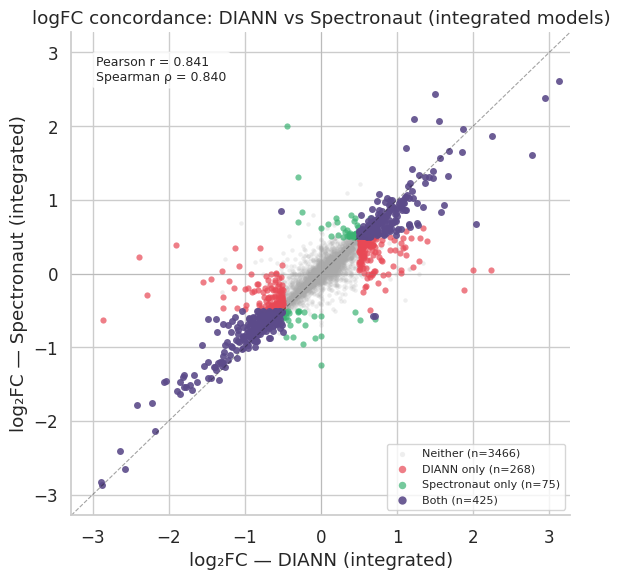

Pearson r = 0.841  (p = 0.00e+00)
Spearman ρ = 0.840  (p = 0.00e+00)


In [6]:
palette_sig = {
    'Both':             '#5C4B8A',
    'DIANN only':       '#E84855',
    'Spectronaut only': '#3BB273',
    'Neither':          '#AAAAAA',
}
order  = ['Neither', 'DIANN only', 'Spectronaut only', 'Both']
alphas = {'Neither': 0.2, 'DIANN only': 0.7, 'Spectronaut only': 0.7, 'Both': 0.9}
sizes  = {'Neither': 10,  'DIANN only': 20,  'Spectronaut only': 20,  'Both': 25}

r,   _       = stats.pearsonr(merged['logFC_diann'], merged['logFC_spect'])
rho, p_spear = stats.spearmanr(merged['logFC_diann'], merged['logFC_spect'])

fig, ax = plt.subplots(figsize=(6, 6))
for grp in order:
    sub = merged[merged.sig_group == grp]
    ax.scatter(sub['logFC_diann'], sub['logFC_spect'],
               c=palette_sig[grp], s=sizes[grp], alpha=alphas[grp],
               label=f"{grp} (n={len(sub)})", linewidths=0)

lim = max(merged['logFC_diann'].abs().max(), merged['logFC_spect'].abs().max()) * 1.05
ax.plot([-lim, lim], [-lim, lim], 'k--', lw=0.8, alpha=0.4)
ax.axhline(0, color='grey', lw=0.5, alpha=0.3)
ax.axvline(0, color='grey', lw=0.5, alpha=0.3)
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_xlabel("log₂FC — DIANN (integrated)")
ax.set_ylabel("log₂FC — Spectronaut (integrated)")
ax.set_title("logFC concordance: DIANN vs Spectronaut (integrated models)")
ax.legend(fontsize=8, markerscale=1.2, framealpha=0.8)
ax.text(0.05, 0.95, f"Pearson r = {r:.3f}\nSpearman ρ = {rho:.3f}",
        transform=ax.transAxes, va='top', fontsize=9,
        bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.7))
sns.despine()
plt.tight_layout()
save_fig("D3_logFC_scatter_integrated", bbox_inches='tight')
plt.show()
print(f"Pearson r = {r:.3f}  (p = {stats.pearsonr(merged['logFC_diann'], merged['logFC_spect'])[1]:.2e})")
print(f"Spearman ρ = {rho:.3f}  (p = {p_spear:.2e})")

## 5. Significance Overlap

Among proteins detected by both integrated models, how many are significant under each tool's own criteria (FDR < 0.05, |log₂FC| > 0.5)?

Contingency table (shared proteins only):
sig_spect      Not sig Spectronaut  Sig Spectronaut
sig_diann                                          
Not sig DIANN                 3466               75
Sig DIANN                      268              425



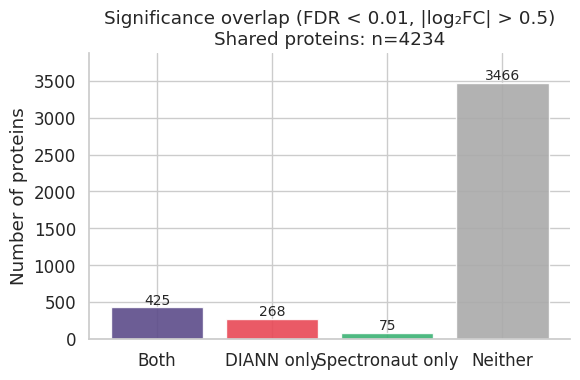

In [24]:
# 2×2 contingency table
ct = pd.crosstab(
    merged['sig_diann'].map({True: 'Sig DIANN', False: 'Not sig DIANN'}),
    merged['sig_spect'].map({True: 'Sig Spectronaut', False: 'Not sig Spectronaut'})
)
print("Contingency table (shared proteins only):")
print(ct)
print()

# Bar chart of the four groups
group_counts = merged['sig_group'].value_counts().reindex(
    ['Both', 'DIANN only', 'Spectronaut only', 'Neither'], fill_value=0
)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(group_counts.index, group_counts.values,
              color=[palette_sig[g] for g in group_counts.index], alpha=0.9)
for bar, v in zip(bars, group_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
            str(v), ha='center', va='bottom', fontsize=10)
ax.set_ylabel("Number of proteins")
ax.set_title(f"Significance overlap (FDR < {FDR_THRESHOLD}, |log₂FC| > {FC_THRESHOLD})\n"
             f"Shared proteins: n={len(merged)}")
ax.set_ylim(0, group_counts.max() * 1.12)
sns.despine()
plt.tight_layout()
save_fig("D4_significance_overlap_bar", bbox_inches='tight')
plt.show()

/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/data.py:303: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/home/sam/miniconda3/envs/sci_env/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linew

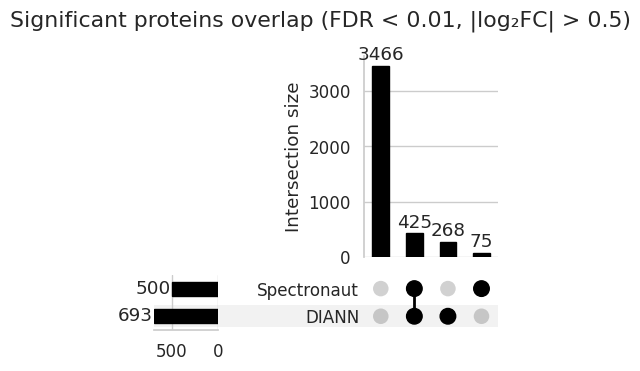

In [7]:
# UpSet showing significance overlap
sig_memberships = [
    [
        lbl
        for lbl, cond in [
            ("DIANN",       row.sig_diann),
            ("Spectronaut", row.sig_spect),
        ]
        if cond
    ]
    for _, row in merged.iterrows()
]
sig_upset_data = from_memberships(sig_memberships)

fig = plt.figure(figsize=(6, 4))
upset = UpSet(sig_upset_data, subset_size='count', show_counts=True,
              sort_by='cardinality')
upset.plot(fig)
fig.suptitle(
    f"Significant proteins overlap (FDR < {FDR_THRESHOLD}, |log₂FC| > {FC_THRESHOLD})",
    y=1.01
)
save_fig("D4_significance_overlap_upset", bbox_inches='tight')
plt.show()

## 6. Per-Plate logFC Concordance

For each of the 9 plates, compare the per-plate MSqRob logFC estimates from DIANN and Spectronaut.
Only proteins quantified on that plate by both tools are included.

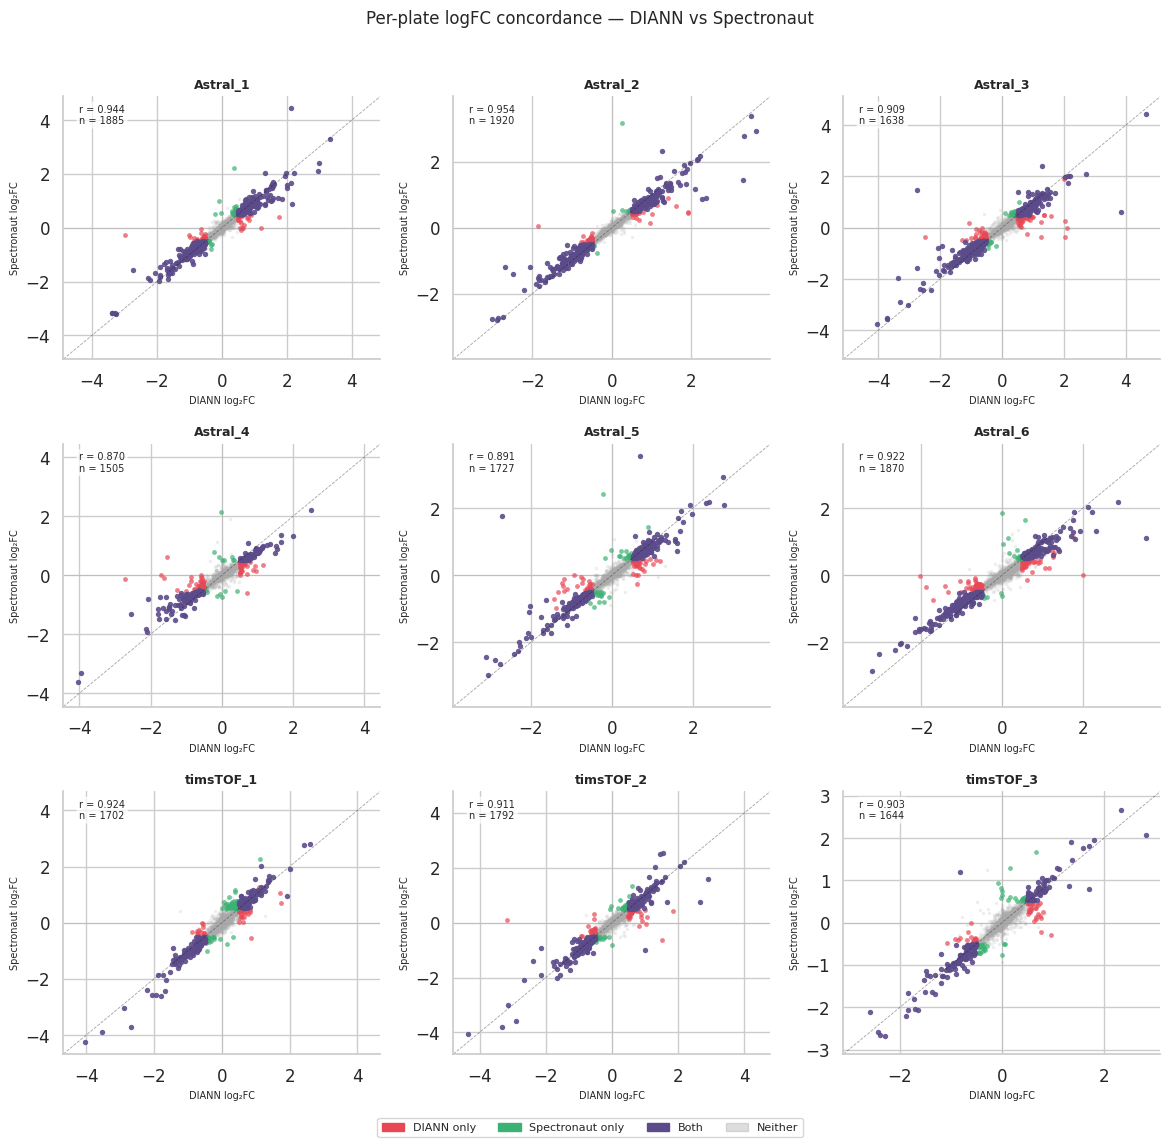

    plate    n  pearson_r  spearman_rho
 Astral_1 1885   0.944460      0.946798
 Astral_2 1920   0.954359      0.970823
 Astral_3 1638   0.909419      0.917648
 Astral_4 1505   0.870478      0.858463
 Astral_5 1727   0.891024      0.911474
 Astral_6 1870   0.922107      0.916493
timsTOF_1 1702   0.924138      0.864628
timsTOF_2 1792   0.910701      0.918193
timsTOF_3 1644   0.903127      0.867442


In [8]:
fig, axes = plt.subplots(3, 3, figsize=(12, 11))
axes_flat = axes.flatten()

corr_summary = []

for ax, plate in zip(axes_flat, PLATE_ORDER):
    d = diann_pp[diann_pp.plate == plate][['protein', 'logFC', 'adjPval']].copy()
    d.columns = ['protein', 'logFC_diann', 'adjPval_diann']

    s = spect_pp[spect_pp.plate == plate][['protein', 'logFC', 'adjPval']].copy()
    s.columns = ['protein', 'logFC_spect', 'adjPval_spect']

    m = d.merge(s, on='protein').dropna(subset=['logFC_diann', 'logFC_spect'])

    m['sig_d'] = is_sig(m.adjPval_diann, m.logFC_diann)
    m['sig_s'] = is_sig(m.adjPval_spect, m.logFC_spect)

    def sig_lbl(row):
        if row.sig_d and row.sig_s:
            return 'Both'
        elif row.sig_d:
            return 'DIANN only'
        elif row.sig_s:
            return 'Spectronaut only'
        return 'Neither'

    m['grp'] = m.apply(sig_lbl, axis=1)

    r = rho = np.nan
    if len(m) >= 5:
        r, _   = stats.pearsonr(m.logFC_diann, m.logFC_spect)
        rho, _ = stats.spearmanr(m.logFC_diann, m.logFC_spect)

    corr_summary.append({'plate': plate, 'n': len(m), 'pearson_r': r, 'spearman_rho': rho})

    for grp in order:
        sub = m[m.grp == grp]
        ax.scatter(sub.logFC_diann, sub.logFC_spect,
                   c=palette_sig[grp], s=sizes[grp] * 0.6,
                   alpha=alphas[grp], linewidths=0)

    lim = max(
        np.abs(m.logFC_diann).max() if len(m) else 1,
        np.abs(m.logFC_spect).max() if len(m) else 1
    ) * 1.1
    ax.plot([-lim, lim], [-lim, lim], 'k--', lw=0.6, alpha=0.4)
    ax.axhline(0, color='grey', lw=0.4, alpha=0.3)
    ax.axvline(0, color='grey', lw=0.4, alpha=0.3)
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_title(plate, fontsize=9, fontweight='bold')
    ax.set_xlabel("DIANN log₂FC", fontsize=7)
    ax.set_ylabel("Spectronaut log₂FC", fontsize=7)
    ax.text(0.05, 0.97, f"r = {r:.3f}\nn = {len(m)}",
            transform=ax.transAxes, va='top', fontsize=7,
            bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.7))

# Legend
patches = [mpatches.Patch(color=palette_sig[g], label=g) for g in order if g != 'Neither']
patches.append(mpatches.Patch(color=palette_sig['Neither'], label='Neither', alpha=0.4))
fig.legend(handles=patches, loc='lower center', ncol=4,
           fontsize=8, bbox_to_anchor=(0.5, -0.02))

fig.suptitle("Per-plate logFC concordance — DIANN vs Spectronaut", fontsize=12, y=1.01)
sns.despine()
plt.tight_layout()
save_fig("D5_logFC_per_plate_grid", bbox_inches='tight')
plt.show()

corr_df = pd.DataFrame(corr_summary)
print(corr_df.to_string(index=False))

/tmp/ipykernel_2652529/3498212089.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(corr_df.plate, rotation=35, ha='right')


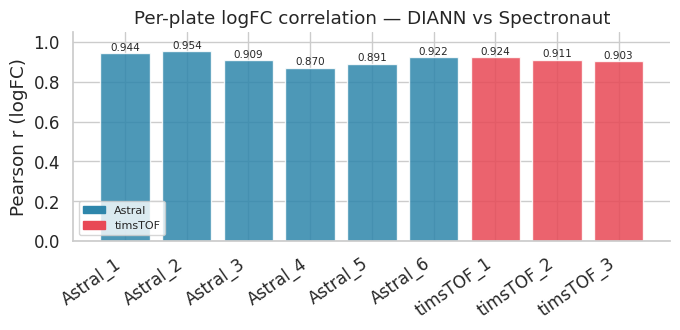

In [27]:
# Pearson r per plate — summary barplot
fig, ax = plt.subplots(figsize=(7, 3.5))
colors = ['#2E86AB' if p.startswith('Astral') else '#E84855'
          for p in corr_df.plate]
bars = ax.bar(corr_df.plate, corr_df.pearson_r, color=colors, alpha=0.85)
for bar, v in zip(bars, corr_df.pearson_r):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.003,
            f"{v:.3f}", ha='center', va='bottom', fontsize=7.5)
ax.set_ylim(0, 1.05)
ax.set_xticklabels(corr_df.plate, rotation=35, ha='right')
ax.set_ylabel("Pearson r (logFC)")
ax.set_title("Per-plate logFC correlation — DIANN vs Spectronaut")
astral_patch  = mpatches.Patch(color='#2E86AB', label='Astral')
timstof_patch = mpatches.Patch(color='#E84855', label='timsTOF')
ax.legend(handles=[astral_patch, timstof_patch], fontsize=8)
sns.despine()
plt.tight_layout()
save_fig("D5_pearson_r_per_plate", bbox_inches='tight')
plt.show()

## 7. Direction-of-Effect Agreement

Among proteins significant in at least one tool, check whether they agree on the sign of the logFC (K562 vs HEK293T direction).

In [28]:
# For each plate: among proteins sig in both, what fraction agree on sign?
direction_rows = []
for plate in PLATE_ORDER:
    d = diann_pp[diann_pp.plate == plate][['protein', 'logFC', 'adjPval']].copy()
    d.columns = ['protein', 'logFC_diann', 'adjPval_diann']
    s = spect_pp[spect_pp.plate == plate][['protein', 'logFC', 'adjPval']].copy()
    s.columns = ['protein', 'logFC_spect', 'adjPval_spect']
    m = d.merge(s, on='protein').dropna()

    sig_both = m[
        is_sig(m.adjPval_diann, m.logFC_diann) &
        is_sig(m.adjPval_spect, m.logFC_spect)
    ]

    sig_either = m[
        is_sig(m.adjPval_diann, m.logFC_diann) |
        is_sig(m.adjPval_spect, m.logFC_spect)
    ]

    if len(sig_both) > 0:
        agree = (np.sign(sig_both.logFC_diann) == np.sign(sig_both.logFC_spect)).mean()
    else:
        agree = np.nan

    if len(sig_either) > 0:
        agree_either = (np.sign(sig_either.logFC_diann) == np.sign(sig_either.logFC_spect)).mean()
    else:
        agree_either = np.nan

    direction_rows.append({
        'plate': plate,
        'n_shared': len(m),
        'n_sig_both': len(sig_both),
        'n_sig_either': len(sig_either),
        'direction_agree_sig_both': agree,
        'direction_agree_sig_either': agree_either,
    })

direction_df = pd.DataFrame(direction_rows)
print(direction_df.to_string(index=False))

    plate  n_shared  n_sig_both  n_sig_either  direction_agree_sig_both  direction_agree_sig_either
 Astral_1      1885         315           433                  1.000000                    0.983834
 Astral_2      1920         336           452                  1.000000                    0.997788
 Astral_3      1638         326           470                  0.996933                    0.985106
 Astral_4      1505         146           260                  1.000000                    0.969231
 Astral_5      1727         227           350                  0.995595                    0.982857
 Astral_6      1870         247           403                  1.000000                    0.995037
timsTOF_1      1702         229           364                  1.000000                    0.986264
timsTOF_2      1792         258           385                  0.996124                    0.974026
timsTOF_3      1644         161           261                  0.993789                    0.957854


## 8. Outliers — Opposite-Direction Significant Proteins

Proteins that are significant in **both** tools (FDR < 0.05, |log₂FC| > 0.5) but with **opposite signs** of logFC are the most concerning discordances: both tools are confident, yet they disagree on which condition the protein is higher in.

These proteins sit in the off-diagonal quadrants (top-left / bottom-right) of the integrated logFC scatter.

In [29]:
# ── Extract opposite-direction outliers ───────────────────────────────────────
sig_both = merged[merged.sig_group == 'Both'].copy()
outliers = sig_both[
    np.sign(sig_both['logFC_diann']) != np.sign(sig_both['logFC_spect'])
].copy()

# Rank by total disagreement: sum of absolute logFCs (most extreme first)
outliers['disagreement'] = outliers['logFC_diann'].abs() + outliers['logFC_spect'].abs()
outliers = outliers.sort_values('disagreement', ascending=False).reset_index(drop=True)

print(f"Proteins significant in both tools (n={len(sig_both)}):")
print(f"  Concordant direction  : {(np.sign(sig_both.logFC_diann) == np.sign(sig_both.logFC_spect)).sum()}")
print(f"  Opposite direction    : {len(outliers)}")
print()

if len(outliers) == 0:
    print("No opposite-direction outliers found.")
else:
    display_cols = {
        'protein':       'Protein',
        'logFC_diann':   'logFC (DIANN)',
        'adjPval_diann': 'adjPval (DIANN)',
        'logFC_spect':   'logFC (Spectronaut)',
        'adjPval_spect': 'adjPval (Spectronaut)',
        'disagreement':  'Disagreement (|logFC| sum)',
    }
    tbl = (
        outliers[list(display_cols)]
        .rename(columns=display_cols)
        .style
        .format({
            'logFC (DIANN)':            '{:+.3f}',
            'adjPval (DIANN)':          '{:.2e}',
            'logFC (Spectronaut)':      '{:+.3f}',
            'adjPval (Spectronaut)':    '{:.2e}',
            'Disagreement (|logFC| sum)': '{:.3f}',
        })
        .background_gradient(subset='Disagreement (|logFC| sum)', cmap='OrRd')
        .applymap(lambda v: 'color: #2E86AB' if isinstance(v, str) and v.startswith('+') else
                            ('color: #E84855' if isinstance(v, str) and v.startswith('-') else ''),
                  subset=['logFC (DIANN)', 'logFC (Spectronaut)'])
    )
    display(tbl)

Proteins significant in both tools (n=425):
  Concordant direction  : 422
  Opposite direction    : 3



/tmp/ipykernel_2652529/2609791730.py:39: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  .applymap(lambda v: 'color: #2E86AB' if isinstance(v, str) and v.startswith('+') else


,Protein,logFC (DIANN),adjPval (DIANN),logFC (Spectronaut),adjPval (Spectronaut),Disagreement (|logFC| sum)
0,Q8IYD1,-0.527,2.15e-17,+0.846,1.40e-03,1.373
1,Q99439,+0.712,1.11e-71,-0.572,4.70e-15,1.283
2,P07197,+0.678,3.13e-06,-0.579,1.25e-18,1.257


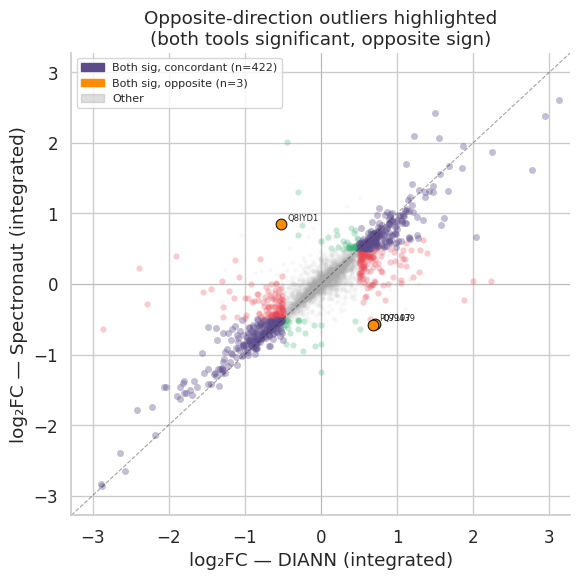

In [30]:
# ── Scatter: highlight outliers ───────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(6, 6))

# Background: all sig_group points, dimmed
for grp in order:
    sub = merged[merged.sig_group == grp]
    ax.scatter(sub['logFC_diann'], sub['logFC_spect'],
               c=palette_sig[grp], s=sizes[grp], alpha=alphas[grp] * 0.4,
               linewidths=0)

if len(outliers) > 0:
    ax.scatter(outliers['logFC_diann'], outliers['logFC_spect'],
               c='#FF8C00', s=60, alpha=1.0, zorder=5,
               edgecolors='black', linewidths=0.7,
               label=f'Opposite direction (n={len(outliers)})')
    # Annotate top 10 by disagreement
    for _, row in outliers.head(10).iterrows():
        label = row['protein'].split(';')[0]   # first accession if semicolon-separated
        ax.annotate(label, (row['logFC_diann'], row['logFC_spect']),
                    fontsize=6, xytext=(5, 3), textcoords='offset points',
                    arrowprops=dict(arrowstyle='-', lw=0.4, color='grey'))

lim = max(merged['logFC_diann'].abs().max(), merged['logFC_spect'].abs().max()) * 1.05
ax.plot([-lim, lim], [-lim, lim], 'k--', lw=0.8, alpha=0.4)
ax.axhline(0, color='grey', lw=0.5, alpha=0.3)
ax.axvline(0, color='grey', lw=0.5, alpha=0.3)
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_xlabel("log₂FC — DIANN (integrated)")
ax.set_ylabel("log₂FC — Spectronaut (integrated)")
ax.set_title("Opposite-direction outliers highlighted\n(both tools significant, opposite sign)")

# Custom legend
legend_handles = [
    mpatches.Patch(color=palette_sig['Both'],    label=f"Both sig, concordant (n={len(sig_both) - len(outliers)})"),
    mpatches.Patch(color='#FF8C00',              label=f"Both sig, opposite (n={len(outliers)})"),
    mpatches.Patch(color=palette_sig['Neither'], label='Other', alpha=0.4),
]
ax.legend(handles=legend_handles, fontsize=8, framealpha=0.8)
sns.despine()
plt.tight_layout()
save_fig("D6_outlier_scatter", bbox_inches='tight')
plt.show()

In [31]:
# ── Per-plate logFC for outlier proteins ──────────────────────────────────────
# Check whether the direction disagreement is consistent across plates or plate-specific.
if len(outliers) == 0:
    print("No outliers to inspect per plate.")
else:
    outlier_proteins = outliers['protein'].tolist()

    rows = []
    for plate in PLATE_ORDER:
        d = diann_pp[diann_pp.plate == plate][['protein', 'logFC']].rename(columns={'logFC': 'DIANN'})
        s = spect_pp[spect_pp.plate == plate][['protein', 'logFC']].rename(columns={'logFC': 'Spectronaut'})
        m = d.merge(s, on='protein')
        m = m[m.protein.isin(outlier_proteins)].copy()
        m['plate'] = plate
        rows.append(m)

    pp_outliers = pd.concat(rows, ignore_index=True)

    # Pivot to wide: rows = protein, columns = (plate, tool)
    pivot = pp_outliers.pivot_table(index='protein', columns='plate',
                                     values=['DIANN', 'Spectronaut'])
    pivot.columns = [f"{tool}\n{plate}" for tool, plate in pivot.columns]
    pivot = pivot.reindex(outlier_proteins)   # keep disagreement-rank order

    print("Per-plate log₂FC for opposite-direction outliers")
    print("(NaN = protein not quantified in that plate by that tool)\n")

    def color_logfc(val):
        if pd.isna(val):
            return 'color: grey'
        return 'color: #2E86AB' if val > 0 else 'color: #E84855'

    display(
        pivot.style
        .format('{:+.2f}', na_rep='—')
        .applymap(color_logfc)
        .set_caption("Blue = positive logFC (higher in K562), Red = negative (higher in HEK293T)")
    )

Per-plate log₂FC for opposite-direction outliers
(NaN = protein not quantified in that plate by that tool)



/tmp/ipykernel_2652529/1681101015.py:36: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  .applymap(color_logfc)


,DIANN Astral_1,DIANN Astral_2,DIANN Astral_4,DIANN Astral_5,DIANN Astral_6,DIANN timsTOF_2,Spectronaut Astral_1,Spectronaut Astral_3,Spectronaut Astral_4,Spectronaut Astral_5,Spectronaut timsTOF_1,Spectronaut timsTOF_2,Spectronaut timsTOF_3
protein,,,,,,,,,,,,,
Q8IYD1,—,—,—,—,—,—,—,—,—,—,—,—,—
Q99439,—,—,—,—,—,—,—,—,—,—,—,—,—
P07197,-0.10,+0.36,+0.42,+0.14,-0.04,+0.00,-0.19,-0.09,-0.53,-0.30,-0.68,-0.83,-0.55


### Per-plate discordant proteins

Repeat the same criterion plate-by-plate using the per-plate MSqRob results. This gives a larger set and reveals whether discordance is consistent across plates (systematic) or restricted to individual plates (noisy/plate-specific).

In [32]:
# ── Per-plate opposite-direction outliers ─────────────────────────────────────
pp_outlier_rows = []

for plate in PLATE_ORDER:
    d = diann_pp[diann_pp.plate == plate][['protein', 'logFC', 'adjPval']].copy()
    d.columns = ['protein', 'logFC_diann', 'adjPval_diann']
    s = spect_pp[spect_pp.plate == plate][['protein', 'logFC', 'adjPval']].copy()
    s.columns = ['protein', 'logFC_spect', 'adjPval_spect']

    m = d.merge(s, on='protein').dropna(
        subset=['logFC_diann', 'adjPval_diann', 'logFC_spect', 'adjPval_spect']
    )
    m['sig_d'] = is_sig(m['adjPval_diann'], m['logFC_diann'])
    m['sig_s'] = is_sig(m['adjPval_spect'], m['logFC_spect'])

    both_sig = m[m['sig_d'] & m['sig_s']]
    opp = both_sig[np.sign(both_sig['logFC_diann']) != np.sign(both_sig['logFC_spect'])].copy()
    opp['plate'] = plate
    opp['disagreement'] = opp['logFC_diann'].abs() + opp['logFC_spect'].abs()
    pp_outlier_rows.append(opp)

pp_outliers_df = pd.concat(pp_outlier_rows, ignore_index=True)

# ── Summary per plate ──────────────────────────────────────────────────────────
plate_summary = (
    pp_outliers_df.groupby('plate', observed=True)
    .agg(n_discordant=('protein', 'nunique'),
         mean_disagreement=('disagreement', 'mean'))
    .reindex(PLATE_ORDER)
    .reset_index()
)

print("Opposite-direction proteins per plate (sig in both tools):")
print(plate_summary.to_string(index=False))
print(f"\nTotal unique discordant proteins across all plates : {pp_outliers_df['protein'].nunique()}")
print(f"Integrated-model discordant proteins              : {len(outliers)}")

# Combined set: union of integrated + any per-plate discordant
all_discordant = set(outliers['protein']) | set(pp_outliers_df['protein'])
print(f"Union (integrated ∪ per-plate)                    : {len(all_discordant)}")

Opposite-direction proteins per plate (sig in both tools):
    plate  n_discordant  mean_disagreement
 Astral_1           NaN                NaN
 Astral_2           NaN                NaN
 Astral_3           1.0           4.191018
 Astral_4           NaN                NaN
 Astral_5           1.0           4.481623
 Astral_6           NaN                NaN
timsTOF_1           NaN                NaN
timsTOF_2           1.0           1.996182
timsTOF_3           1.0           2.014699

Total unique discordant proteins across all plates : 2
Integrated-model discordant proteins              : 3
Union (integrated ∪ per-plate)                    : 5


In [33]:
# ── Protein-level summary: in how many plates is each protein discordant? ─────
plate_counts = (
    pp_outliers_df.groupby('protein')
    .agg(
        n_plates_discordant=('plate', 'nunique'),
        plates=('plate', lambda x: ', '.join(sorted(set(x)))),
        mean_disagreement=('disagreement', 'mean'),
    )
    .sort_values(['n_plates_discordant', 'mean_disagreement'], ascending=[False, False])
    .reset_index()
)

# Flag whether the protein also appears in the integrated-model outlier set
plate_counts['in_integrated'] = plate_counts['protein'].isin(set(outliers['protein']))

print(f"Proteins discordant in ≥2 plates: {(plate_counts.n_plates_discordant >= 2).sum()}")
print(f"Proteins discordant in ≥3 plates: {(plate_counts.n_plates_discordant >= 3).sum()}")
print()

display(
    plate_counts.rename(columns={
        'protein':              'Protein',
        'n_plates_discordant':  '# plates discordant',
        'plates':               'Plates',
        'mean_disagreement':    'Mean disagreement',
        'in_integrated':        'Also in integrated model',
    })
    .style
    .format({'Mean disagreement': '{:.3f}'})
    .background_gradient(subset='# plates discordant', cmap='YlOrRd')
    .applymap(lambda v: 'font-weight: bold; color: #5C4B8A' if v is True else '',
              subset=['Also in integrated model'])
)

Proteins discordant in ≥2 plates: 1
Proteins discordant in ≥3 plates: 1



/tmp/ipykernel_2652529/2400394188.py:31: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  .applymap(lambda v: 'font-weight: bold; color: #5C4B8A' if v is True else '',


,Protein,# plates discordant,Plates,Mean disagreement,Also in integrated model
0,P16401,3,"Astral_3, Astral_5, timsTOF_3",3.562,False
1,Q15436,1,timsTOF_2,1.996,False


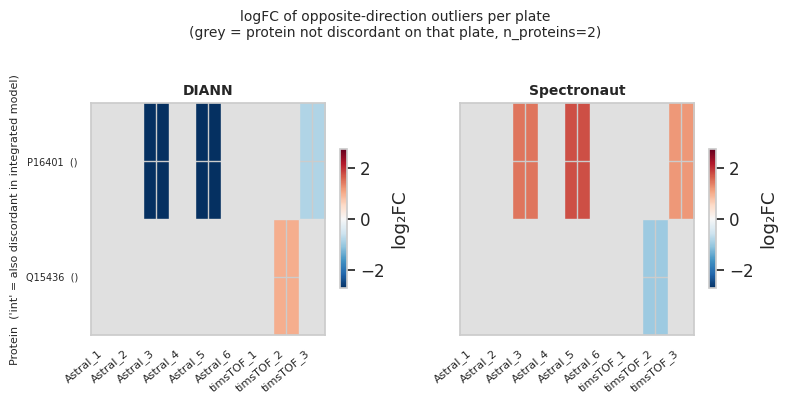

In [34]:
# ── Heatmap: logFC direction for all discordant proteins × plates ─────────────
# Rows = proteins (sorted by n_plates_discordant desc), columns = plates.
# Each cell split into two triangles: upper = DIANN, lower = Spectronaut.
# Color: blue (positive logFC), red (negative), grey (not discordant on that plate).

proteins_sorted = plate_counts['protein'].tolist()

# Build logFC matrices: rows = protein, columns = plate
diann_mat  = pd.DataFrame(index=proteins_sorted, columns=PLATE_ORDER, dtype=float)
spect_mat  = pd.DataFrame(index=proteins_sorted, columns=PLATE_ORDER, dtype=float)
discord_mask = pd.DataFrame(False, index=proteins_sorted, columns=PLATE_ORDER)

for _, row in pp_outliers_df.iterrows():
    p, pl = row['protein'], row['plate']
    if p in diann_mat.index:
        diann_mat.loc[p, pl] = row['logFC_diann']
        spect_mat.loc[p, pl] = row['logFC_spect']
        discord_mask.loc[p, pl] = True

diann_mat  = diann_mat.astype(float)
spect_mat  = spect_mat.astype(float)

n_prot = len(proteins_sorted)
n_plates = len(PLATE_ORDER)

if n_prot == 0:
    print("No per-plate discordant proteins found.")
else:
    vmax = max(
        diann_mat.abs().max().max(),
        spect_mat.abs().max().max()
    )
    # Clamp for display
    vmax = min(vmax, 5.0)

    fig, axes = plt.subplots(1, 2, figsize=(max(8, n_plates * 0.9), max(4, n_prot * 0.55 + 1.5)),
                              sharey=True)

    for ax, mat, tool in zip(axes, [diann_mat, spect_mat], ['DIANN', 'Spectronaut']):
        im = ax.imshow(mat.values, aspect='auto', cmap='RdBu_r',
                       vmin=-vmax, vmax=vmax)
        ax.set_xticks(range(n_plates))
        ax.set_xticklabels(PLATE_ORDER, rotation=40, ha='right', fontsize=8)
        ax.set_yticks(range(n_prot))
        ax.set_yticklabels(
            [f"{p}  ({'int' if p in set(outliers['protein']) else ''})" for p in proteins_sorted],
            fontsize=7
        )
        ax.set_title(tool, fontsize=10, fontweight='bold')
        # Grey out non-discordant cells
        for i, prot in enumerate(proteins_sorted):
            for j, plate in enumerate(PLATE_ORDER):
                if not discord_mask.loc[prot, plate]:
                    ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1,
                                               color='#E0E0E0', zorder=2))
        plt.colorbar(im, ax=ax, label='log₂FC', shrink=0.6)

    axes[0].set_ylabel("Protein  ('int' = also discordant in integrated model)", fontsize=8)
    fig.suptitle(
        f"logFC of opposite-direction outliers per plate\n"
        f"(grey = protein not discordant on that plate, n_proteins={n_prot})",
        fontsize=10, y=1.01
    )
    plt.tight_layout()
    save_fig("D7_outlier_perplate_heatmap", bbox_inches='tight')
    plt.show()

### Investigation plan

For each opposite-direction protein, work through these checks in order. Earlier checks are cheaper and more likely to be the root cause.

---

**1. Is the direction disagreement consistent across plates or plate-specific?**
The per-plate table above already shows this. If the flip is present in only one or two plates, the cause is likely a plate-level technical artefact rather than a systematic difference between the tools (e.g. a single outlier cell driving the estimate).

---

**2. How many precursors/peptides back each protein?**
Proteins quantified by only 1–2 peptides are much more sensitive to missed cleavages, conflicting peptide assignments, or imputation artefacts. Check:
- Number of unique precursors per protein per tool (from the raw DIANN `.pr_matrix` / Spectronaut `PeptideReport.xls`).
- Whether each tool uses a different set of peptides for that protein (tools may select different top-N peptides for quantification).

---

**3. Are there shared / razor peptides involved?**
Peptides shared between protein groups can be assigned to different proteins by DIANN vs Spectronaut depending on their protein inference algorithm. A peptide that drives a positive logFC in protein A in DIANN may be assigned to protein B in Spectronaut. Check:
- Whether the protein identifier is the same or whether one tool collapses isoforms the other separates.
- Whether a protein with many shared peptides (e.g. histone variants, ribosomal proteins) is involved.

---

**4. Check the raw precursor intensities directly**
Before any normalisation or model fitting, look at the precursor-level intensity matrix for these proteins across conditions. A direction flip at the protein level that is not present at the precursor level would indicate a quantification roll-up or normalisation artefact.

---

**5. Normalisation strategy**
DIANN and Spectronaut use different default normalisation (e.g. RT-dependent local normalisation in DIANN vs global median in Spectronaut). A protein that spans a retention-time region with a strong local intensity shift could be normalised in opposite directions. Check whether the raw (unnormalised) intensities already flip direction, or only the normalised ones.

---

**6. Missing-value pattern and imputation**
Proteins with many missing values in one condition are vulnerable to imputation artefacts. If one tool imputes more aggressively (or uses a different strategy), the imputed values can dominate the fold-change estimate. Check:
- Fraction of missing values per condition per tool for each outlier protein.
- Whether MSqRob used imputed or observed values for the relevant cells.

---

**7. UniProt annotation of the outlier proteins**
Look up each protein in UniProt to check:
- Known isoforms or proteoforms with very different expression patterns.
- Membership in a protein family with highly similar sequences (cross-mapping risk in DIA).
- Known issues with DIA quantification (e.g. very short proteins, extreme amino acid composition).

---

**8. Cross-map / spectral interference in DIA**
In DIA, co-eluting precursors with overlapping m/z can cause spectral interference. If one tool's deconvolution assigns interfering signal to this protein but the other does not, the quantification can diverge. Check:
- Whether the protein has precursors that co-elute with other abundant proteins.
- Whether the DIANN confidence scores (e.g. `Cscore`) are markedly lower for this protein compared to concordant proteins.

Counts

In [10]:
spect_pp

,protein,logFC,se,df,t,pval,adjPval,plate
0,O00299,-1.557786,0.040819,208.437281,-38.163439,5.282624e-96,1.100371e-92,Astral_1
1,P22314,1.471621,0.041643,208.132705,35.338751,6.731963e-90,5.839293e-87,Astral_1
2,P12277,1.918219,0.054400,208.443126,35.261305,8.409927e-90,5.839293e-87,Astral_1
3,P51159,-3.157428,0.087052,157.441589,-36.270717,2.411642e-78,1.255863e-75,Astral_1
4,P68036,-1.503367,0.049874,206.463678,-30.143086,1.496156e-77,6.232987e-75,Astral_1
...,...,...,...,...,...,...,...,...
19372,Q9Y394,NaN,NaN,NaN,NaN,NaN,NaN,timsTOF_3
19373,Q9Y3B3,NaN,NaN,NaN,NaN,NaN,NaN,timsTOF_3
19374,Q9Y3E5,NaN,NaN,NaN,NaN,NaN,NaN,timsTOF_3
19375,Q9Y5Y2,NaN,NaN,NaN,NaN,NaN,NaN,timsTOF_3


In [12]:
pval_col_pp = 'adjPval'
pval_col_int = 'adjPval'

if pval_col_pp is None:
    pval_col_pp = 'adjPval'
if pval_col_int is None:
    pval_col_int = 'adjPval'

print("Using p-value column for Spectronaut per-plate:", pval_col_pp)
print("Using p-value column for Spectronaut integrated:", pval_col_int)

def count_hits(df, pval_col, groupby=None):
    mask = df['logFC'].abs() > 0.5
    mask &= df[pval_col].fillna(1) < 0.001
    if groupby is None:
        return df.loc[mask, 'protein'].nunique(), df['protein'].nunique()
    else:
        summary = (
            df.loc[mask]
              .groupby(groupby, observed=True)['protein']
              .nunique()
              .reindex(PLATE_ORDER, fill_value=0)
              .rename('n_hits')
              .reset_index()
        )
        total_tested = (
            df.groupby(groupby, observed=True)['protein']
              .nunique()
              .reindex(PLATE_ORDER, fill_value=0)
              .rename('n_tested')
              .reset_index()
        )
        return summary.merge(total_tested, on=groupby)

plate_hits = count_hits(spect_pp, pval_col_pp, groupby='plate')
plate_hits['pct_hits'] = (plate_hits['n_hits'] / plate_hits['n_tested'] * 100).round(1)

int_hits, int_tested = count_hits(spect_int, pval_col_int)
integrated_row = pd.DataFrame([{
    'plate': 'Integrated',
    'n_hits': int_hits,
    'n_tested': int_tested,
    'pct_hits': round(int_hits / int_tested * 100, 1) if int_tested else np.nan
}])

result_table = pd.concat([plate_hits, integrated_row], ignore_index=True)
result_table

Using p-value column for Spectronaut per-plate: adjPval
Using p-value column for Spectronaut integrated: adjPval


,plate,n_hits,n_tested,pct_hits
0,Astral_1,384,2153,17.8
1,Astral_2,385,2153,17.9
2,Astral_3,376,2153,17.5
3,Astral_4,166,2153,7.7
4,Astral_5,271,2153,12.6
5,Astral_6,282,2153,13.1
6,timsTOF_1,329,2153,15.3
7,timsTOF_2,323,2153,15.0
8,timsTOF_3,238,2153,11.1
9,Integrated,514,6628,7.8


In [19]:
def count_regulated(df, label):
    valid = df.dropna(subset=['logFC', 'adjPval'])
    up = ((valid['logFC'] > FC_THRESHOLD) & (valid['adjPval'] < .001)).sum()
    down = ((valid['logFC'] < -FC_THRESHOLD) & (valid['adjPval'] < .001)).sum()
    return pd.Series({
        'tested': len(valid),
        'up_regulated': int(up),
        'down_regulated': int(down),
        'total_regulated': int(up + down),
    }, name=label)

counts_int = pd.DataFrame([
    count_regulated(diann_all, 'DIANN integrated'),
    count_regulated(spect_int, 'Spectronaut integrated'),
])

counts_int

,tested,up_regulated,down_regulated,total_regulated
DIANN integrated,4758,358,356,714
Spectronaut integrated,4730,259,255,514


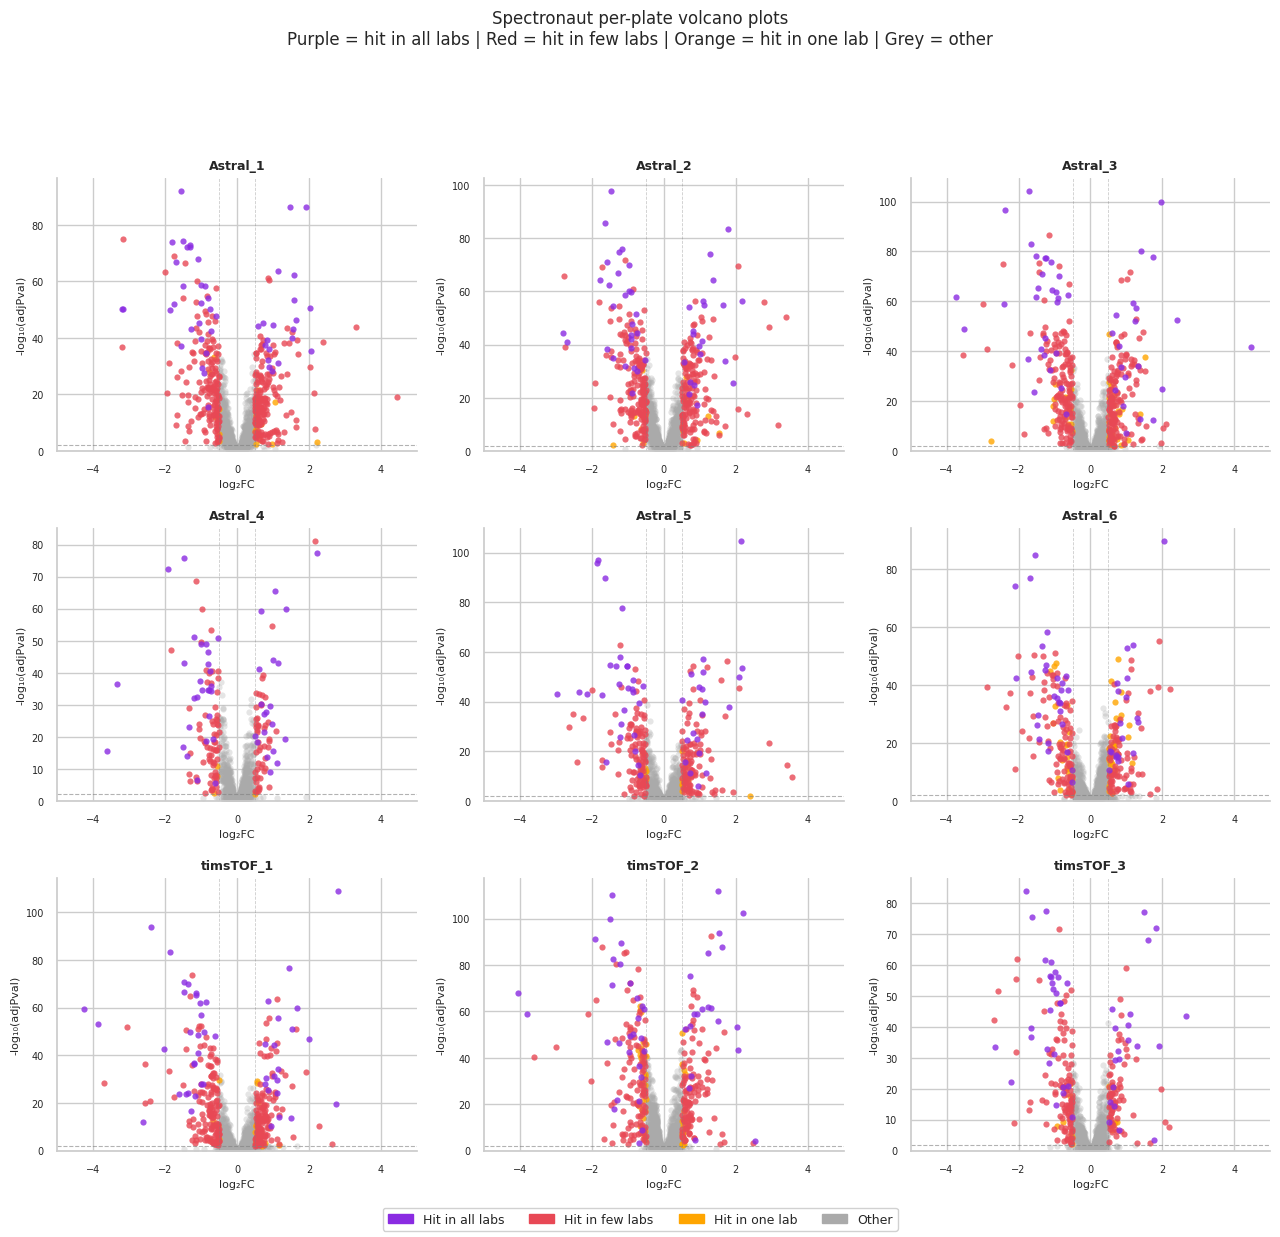

In [16]:
# Volcano panel for Spectronaut per-plate models with custom protein categories

spect_pp['sig'] = is_sig(spect_pp['adjPval'], spect_pp['logFC'])
protein_hit_counts = spect_pp.groupby('protein', observed=True)['sig'].sum()

n_plates = len(PLATE_ORDER)
hit_in_all  = set(protein_hit_counts[protein_hit_counts == n_plates].index)
hit_in_one  = set(protein_hit_counts[protein_hit_counts == 1].index)
hit_in_few  = set(protein_hit_counts[(protein_hit_counts > 1) & (protein_hit_counts < n_plates)].index)

cat_colors = {
    'Hit in all labs':  '#8A2BE2',  # purple
    'Hit in few labs':  '#E84855',  # red
    'Hit in one lab':   '#FFA500',  # orange
    'Other':            '#AAAAAA',  # grey
}

def classify(row):
    p = row['protein']
    if not row['sig']:
        return 'Other'
    if p in hit_in_all:
        return 'Hit in all labs'
    if p in hit_in_few:
        return 'Hit in few labs'
    if p in hit_in_one:
        return 'Hit in one lab'
    return 'Other'

fig, axes = plt.subplots(3, 3, figsize=(13, 12), sharex=False, sharey=False)
axes_flat = axes.flatten()

for ax, plate in zip(axes_flat, PLATE_ORDER):
    sub = spect_pp[spect_pp.plate == plate].copy()
    sub = sub.dropna(subset=['logFC', 'adjPval']).copy()
    sub['neg_log10_p'] = -np.log10(sub['adjPval'].clip(lower=1e-300))
    sub['category'] = sub.apply(classify, axis=1)

    for cat in ['Other', 'Hit in one lab', 'Hit in few labs', 'Hit in all labs']:
        part = sub[sub['category'] == cat]
        ax.scatter(part['logFC'], part['neg_log10_p'],
                   color=cat_colors[cat], s=20,
                   alpha=0.8 if cat != 'Other' else 0.3,
                   label=f"{cat} (n={len(part)})", linewidths=0)

    ax.axhline(-np.log10(FDR_THRESHOLD), color='grey', lw=0.8, ls='--', alpha=0.6)
    ax.axvline(-FC_THRESHOLD, color='grey', lw=0.6, ls='--', alpha=0.4)
    ax.axvline( FC_THRESHOLD, color='grey', lw=0.6, ls='--', alpha=0.4)
    ax.set_title(plate, fontsize=9, fontweight='bold')
    ax.set_xlabel("log₂FC", fontsize=8)
    ax.set_ylabel("-log₁₀(adjPval)", fontsize=8)
    ax.tick_params(labelsize=7)
    ax.set_xlim(-5, 5)
    ax.set_ylim(0, sub['neg_log10_p'].max() * 1.05)

# shared legend
handles = [mpatches.Patch(color=c, label=l) for l, c in cat_colors.items()]
fig.legend(handles=handles, loc='lower center', ncol=4, fontsize=9, framealpha=0.9)

fig.suptitle(
    "Spectronaut per-plate volcano plots\n"
    "Purple = hit in all labs | Red = hit in few labs | Orange = hit in one lab | Grey = other",
    fontsize=12, y=1.02
)
sns.despine(fig=fig)
plt.tight_layout(rect=[0, 0.02, 1, 0.96])
plt.show()

# 8. Outliers

## 9. Volcano Plots per Plate

For each plate, two side-by-side volcano plots — one for DIANN, one for Spectronaut. Proteins are coloured by their significance group across **both** tools:

- **Both** (purple): significant in DIANN and Spectronaut
- **DIANN only** (red): significant in DIANN, not in Spectronaut (or absent from Spectronaut)
- **Spectronaut only** (green): significant in Spectronaut, not in DIANN (or absent from DIANN)
- **Neither** (grey): not significant in either

Each volcano shows all proteins quantified by that tool on that plate — not just shared proteins.

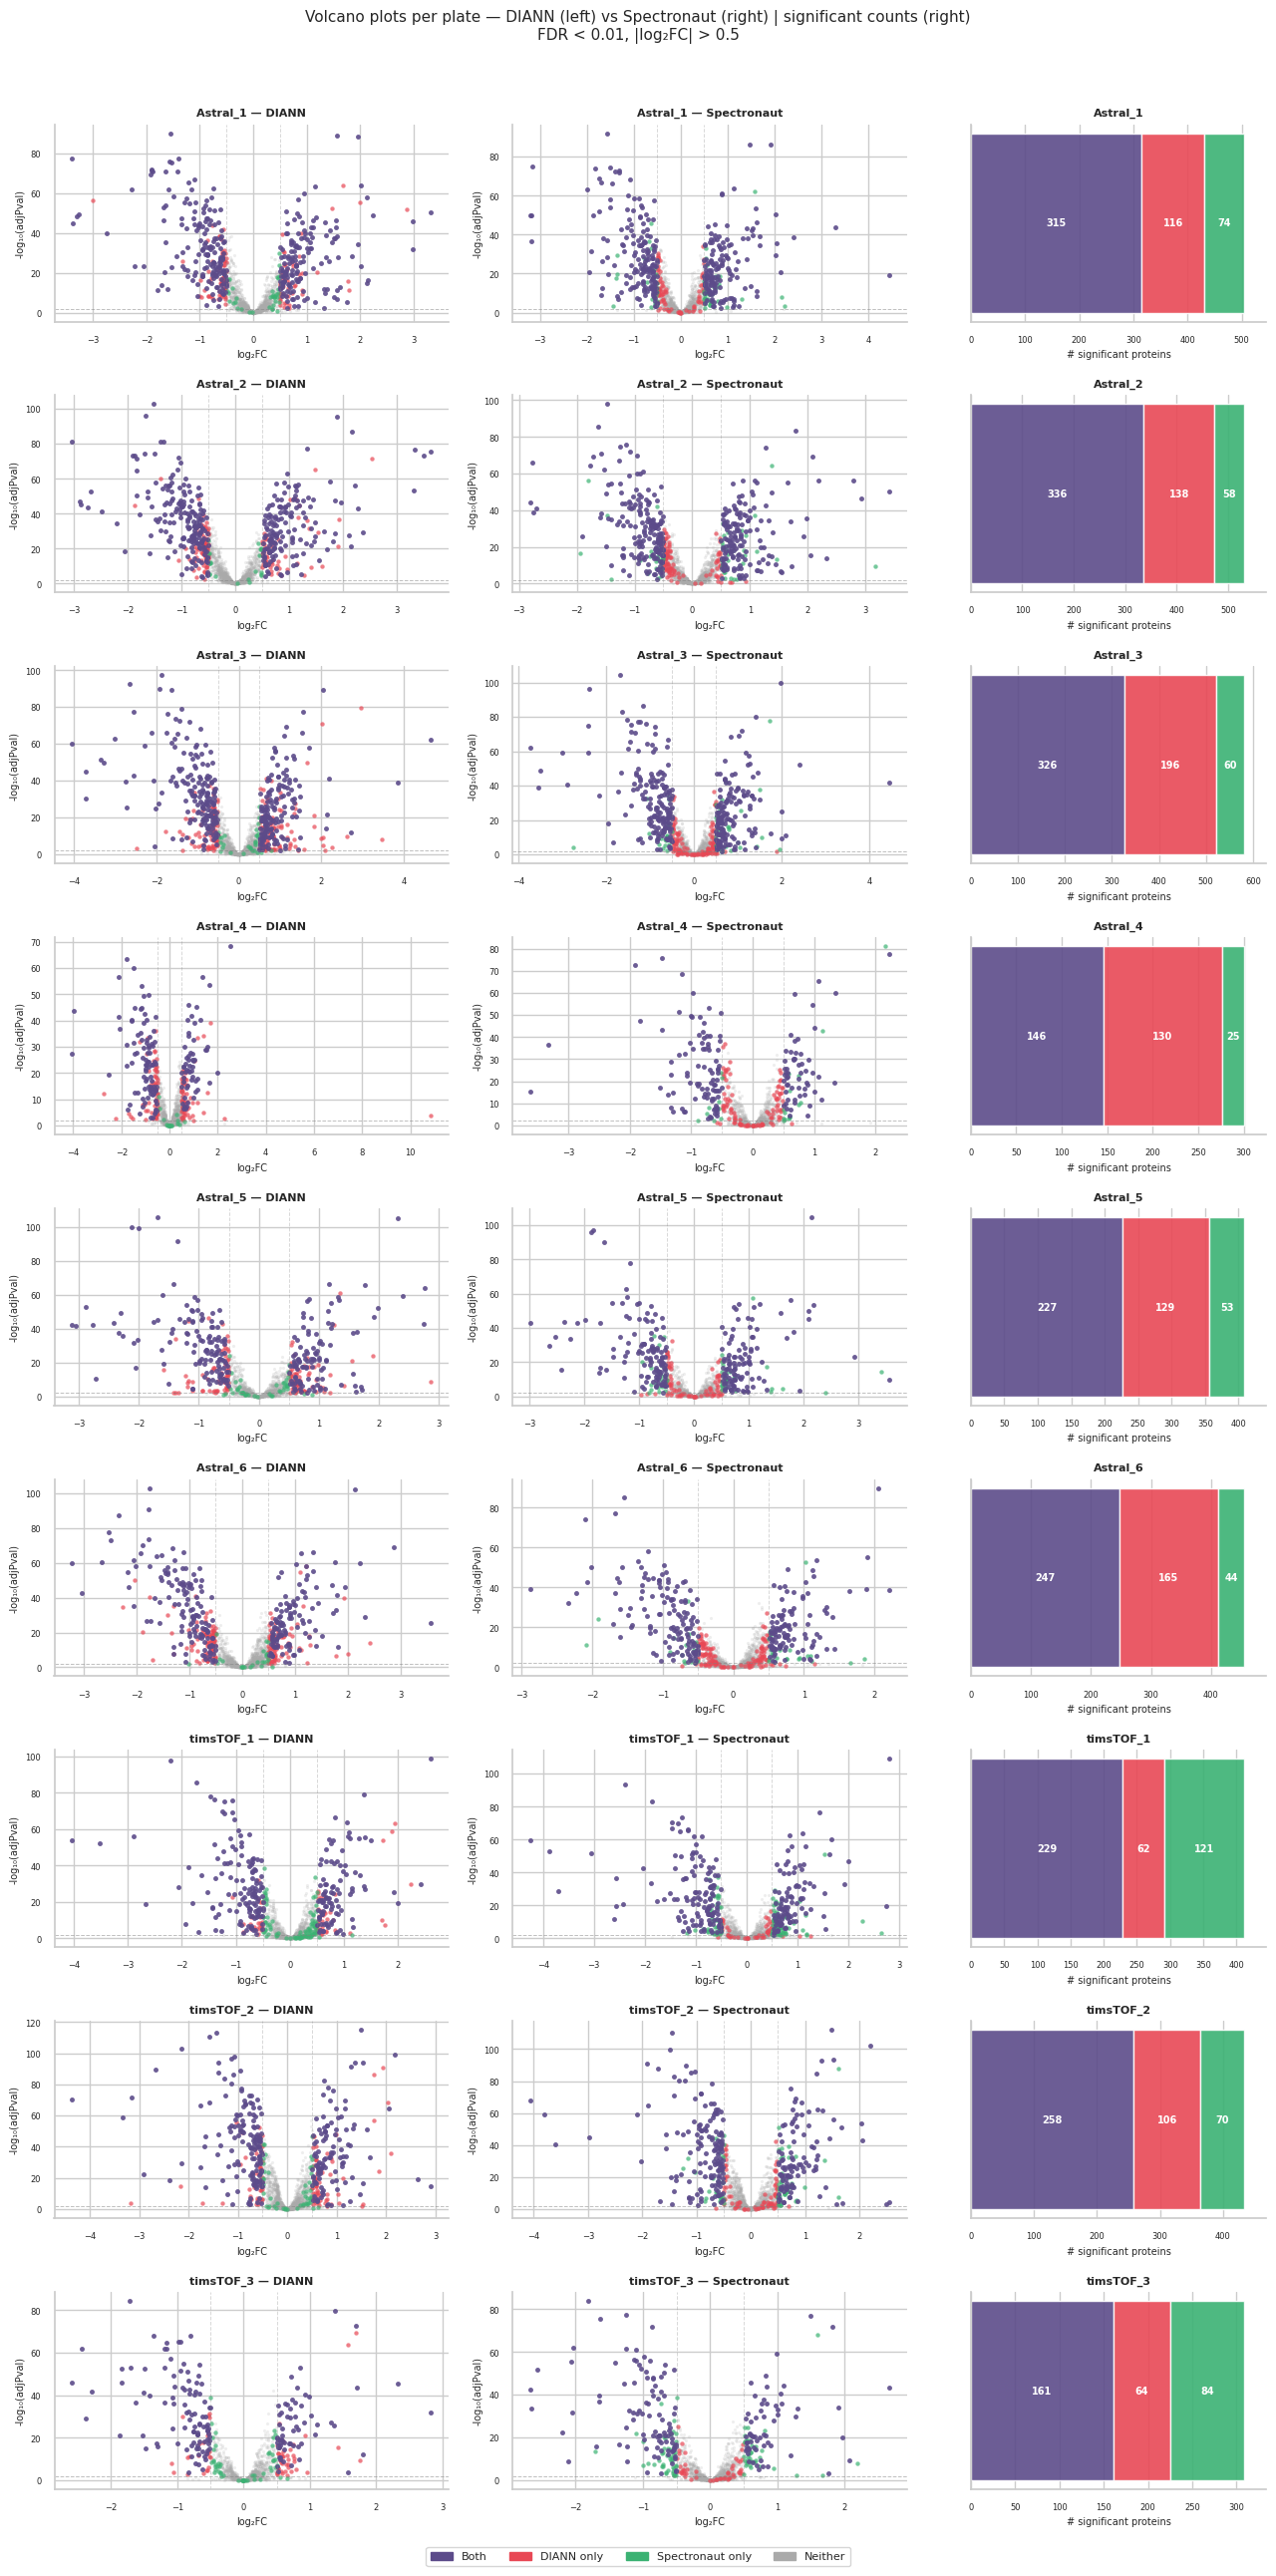

Significant proteins per plate:
           Both  DIANN only  Spectronaut only  Total sig
plate                                                   
Astral_1    315         116                74        505
Astral_2    336         138                58        532
Astral_3    326         196                60        582
Astral_4    146         130                25        301
Astral_5    227         129                53        409
Astral_6    247         165                44        456
timsTOF_1   229          62               121        412
timsTOF_2   258         106                70        434
timsTOF_3   161          64                84        309


In [36]:
sig_groups_ordered = ['Both', 'DIANN only', 'Spectronaut only']
count_rows = []

fig, axes = plt.subplots(
    len(PLATE_ORDER), 3,
    figsize=(13, len(PLATE_ORDER) * 2.8),
    gridspec_kw={'width_ratios': [4, 4, 3]}
)

for row_idx, plate in enumerate(PLATE_ORDER):
    d = diann_pp[diann_pp.plate == plate][['protein', 'logFC', 'adjPval']].copy()
    d.columns = ['protein', 'logFC_diann', 'adjPval_diann']

    s = spect_pp[spect_pp.plate == plate][['protein', 'logFC', 'adjPval']].copy()
    s.columns = ['protein', 'logFC_spect', 'adjPval_spect']

    # Outer merge: retain proteins unique to either tool
    m = d.merge(s, on='protein', how='outer')

    sig_d = is_sig(m['adjPval_diann'].fillna(1), m['logFC_diann'].fillna(0))
    sig_s = is_sig(m['adjPval_spect'].fillna(1), m['logFC_spect'].fillna(0))
    m['grp'] = [
        'Both'             if sd and ss else
        'DIANN only'       if sd         else
        'Spectronaut only' if ss         else
        'Neither'
        for sd, ss in zip(sig_d, sig_s)
    ]

    counts = m['grp'].value_counts()
    count_rows.append({
        'plate': plate,
        **{g: int(counts.get(g, 0)) for g in sig_groups_ordered}
    })

    # ── Volcano plots ────────────────────────────────────────────────────────
    for ax, fc_col, pval_col, tool_label in [
        (axes[row_idx, 0], 'logFC_diann', 'adjPval_diann', 'DIANN'),
        (axes[row_idx, 1], 'logFC_spect', 'adjPval_spect', 'Spectronaut'),
    ]:
        sub_all = m.dropna(subset=[fc_col, pval_col]).copy()
        sub_all['neg_log10_p'] = -np.log10(sub_all[pval_col].clip(lower=1e-300))

        for grp in order:
            sub = sub_all[sub_all.grp == grp]
            ax.scatter(sub[fc_col], sub['neg_log10_p'],
                       c=palette_sig[grp], s=sizes[grp] * 0.5,
                       alpha=alphas[grp], linewidths=0)

        ax.axhline(-np.log10(FDR_THRESHOLD), color='grey', lw=0.7, ls='--', alpha=0.5)
        ax.axvline(-FC_THRESHOLD, color='grey', lw=0.7, ls='--', alpha=0.3)
        ax.axvline( FC_THRESHOLD, color='grey', lw=0.7, ls='--', alpha=0.3)
        ax.set_title(f"{plate} — {tool_label}", fontsize=8, fontweight='bold')
        ax.set_xlabel("log₂FC", fontsize=7)
        ax.set_ylabel("-log₁₀(adjPval)", fontsize=7)
        ax.tick_params(labelsize=6)

    # ── Stacked horizontal bar of significant protein counts ─────────────────
    ax_bar = axes[row_idx, 2]
    left = 0
    grp_counts = [int(counts.get(g, 0)) for g in sig_groups_ordered]
    for g, c in zip(sig_groups_ordered, grp_counts):
        ax_bar.barh(0, c, left=left, color=palette_sig[g], height=0.5, alpha=0.9)
        if c >= 5:
            ax_bar.text(left + c / 2, 0, str(c),
                        ha='center', va='center', fontsize=7,
                        color='white', fontweight='bold')
        left += c

    total = sum(grp_counts)
    ax_bar.set_xlim(0, max(total, 1) * 1.08)
    ax_bar.set_yticks([])
    ax_bar.set_xlabel("# significant proteins", fontsize=7)
    ax_bar.set_title(f"{plate}", fontsize=8, fontweight='bold')
    ax_bar.tick_params(labelsize=6)
    sns.despine(ax=ax_bar, left=True)

# ── Shared legend ────────────────────────────────────────────────────────────
patches = [mpatches.Patch(color=palette_sig[g], label=g)
           for g in ['Both', 'DIANN only', 'Spectronaut only', 'Neither']]
fig.legend(handles=patches, loc='lower center', ncol=4,
           fontsize=8, bbox_to_anchor=(0.5, -0.01))
fig.suptitle(
    f"Volcano plots per plate — DIANN (left) vs Spectronaut (right) | significant counts (right)\n"
    f"FDR < {FDR_THRESHOLD}, |log₂FC| > {FC_THRESHOLD}",
    fontsize=11, y=1.01
)
sns.despine()
plt.tight_layout()
save_fig("D9_volcano_per_plate", bbox_inches='tight')
plt.show()

# ── Summary table ────────────────────────────────────────────────────────────
counts_df = pd.DataFrame(count_rows).set_index('plate')
counts_df['Total sig'] = counts_df[sig_groups_ordered].sum(axis=1)
print("Significant proteins per plate:")
print(counts_df.to_string())